In [1]:
from pathlib import Path

import pandas as pd


def find_data(name="cs-training.csv"):
    """Look for the dataset in the usual repo locations instead of a hard-coded C:\\ path."""
    for p in (Path("data") / name, Path(name), Path("..") / "data" / name):
        if p.exists():
            return p
    raise FileNotFoundError(f"{name} not found. Put it in a 'data/' folder next to this notebook.")


df = pd.read_csv(find_data())
print(df.shape)
df.head()

(150000, 12)


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [2]:
if 'Unnamed: 0' in df.columns:
    df.drop(columns=['Unnamed: 0'], inplace=True)
print("Shape after drop:", df.shape)
print("Columns:", df.columns.tolist())
df.info()
df.describe()

Shape after drop: (150000, 11)
Columns: ['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']
<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCredi

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [3]:
#class imbalance
#0 = this person paid their loan fine. No serious trouble.
#1 = this person missed payments by 90+ days within 2 years. The bank considers this a default.
print("Count:")
print(df["SeriousDlqin2yrs"].value_counts())
print("\nPercentage:")
print(df["SeriousDlqin2yrs"].value_counts(normalize=True).mul(100).round(2).astype(str) + "%")

Count:
SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

Percentage:
SeriousDlqin2yrs
0    93.32%
1     6.68%
Name: proportion, dtype: str


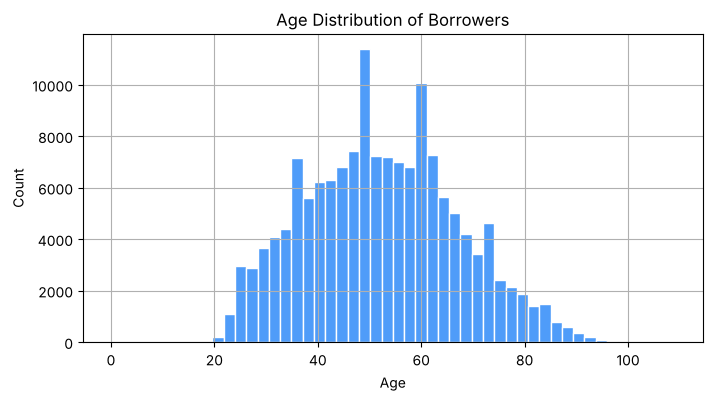

Min age: 0
Max age: 109


In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
df["age"].hist(bins=50, color="#4f9cf9", edgecolor="white")
plt.title("Age Distribution of Borrowers")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()
print("Min age:", df["age"].min())
print("Max age:", df["age"].max())#aged 0 — that's a data error

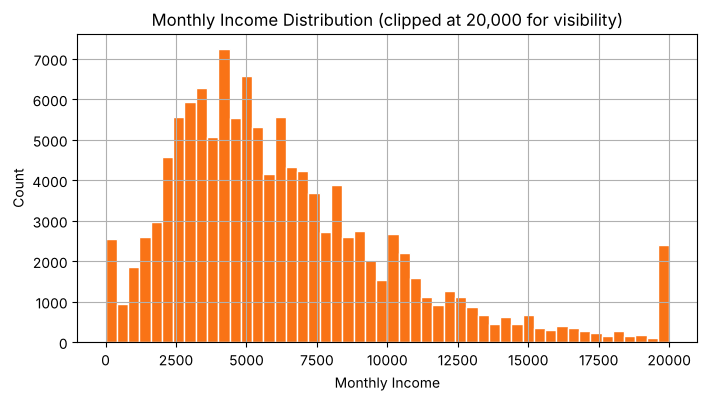

In [5]:
plt.figure(figsize=(8, 4))
df["MonthlyIncome"].dropna().clip(upper=20000).hist(bins=50, color="#f97316", edgecolor="white")
plt.title("Monthly Income Distribution (clipped at 20,000 for visibility)")
plt.xlabel("Monthly Income")
plt.ylabel("Count")
plt.show()

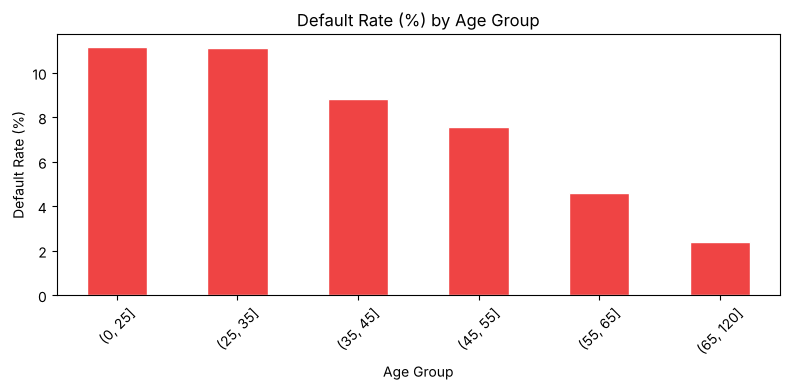

In [6]:
df["age_group"] = pd.cut(df["age"], bins=[0, 25, 35, 45, 55, 65, 120])
default_by_age = df.groupby("age_group", observed=True)["SeriousDlqin2yrs"].mean().mul(100).round(2)
plt.figure(figsize=(8, 4))
default_by_age.plot(kind="bar", color="#ef4444", edgecolor="white")
plt.title("Default Rate (%) by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Clean up temp column
df.drop(columns=["age_group"], inplace=True)

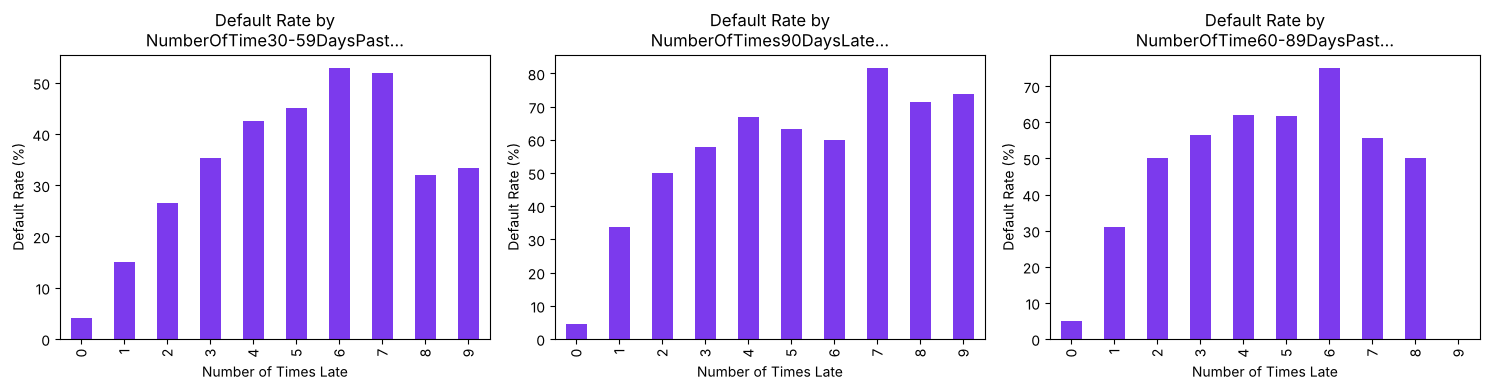

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

late_cols = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse"
]

for ax, col in zip(axes, late_cols):
    df.groupby(col)["SeriousDlqin2yrs"].mean().head(10).mul(100).plot(kind="bar", ax=ax, color="#7c3aed")
    ax.set_title(f"Default Rate by\n{col[:25]}...")
    ax.set_ylabel("Default Rate (%)")
    ax.set_xlabel("Number of Times Late")

plt.tight_layout()
plt.show()

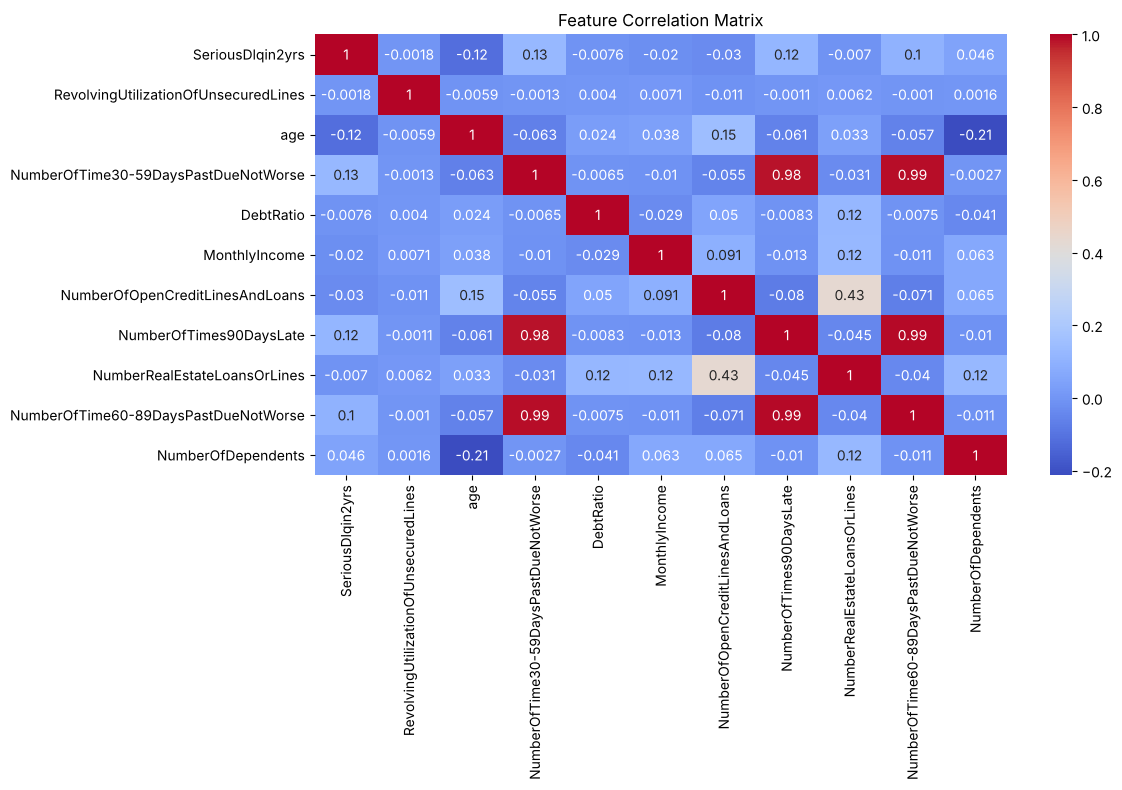

In [8]:
import numpy as np
plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

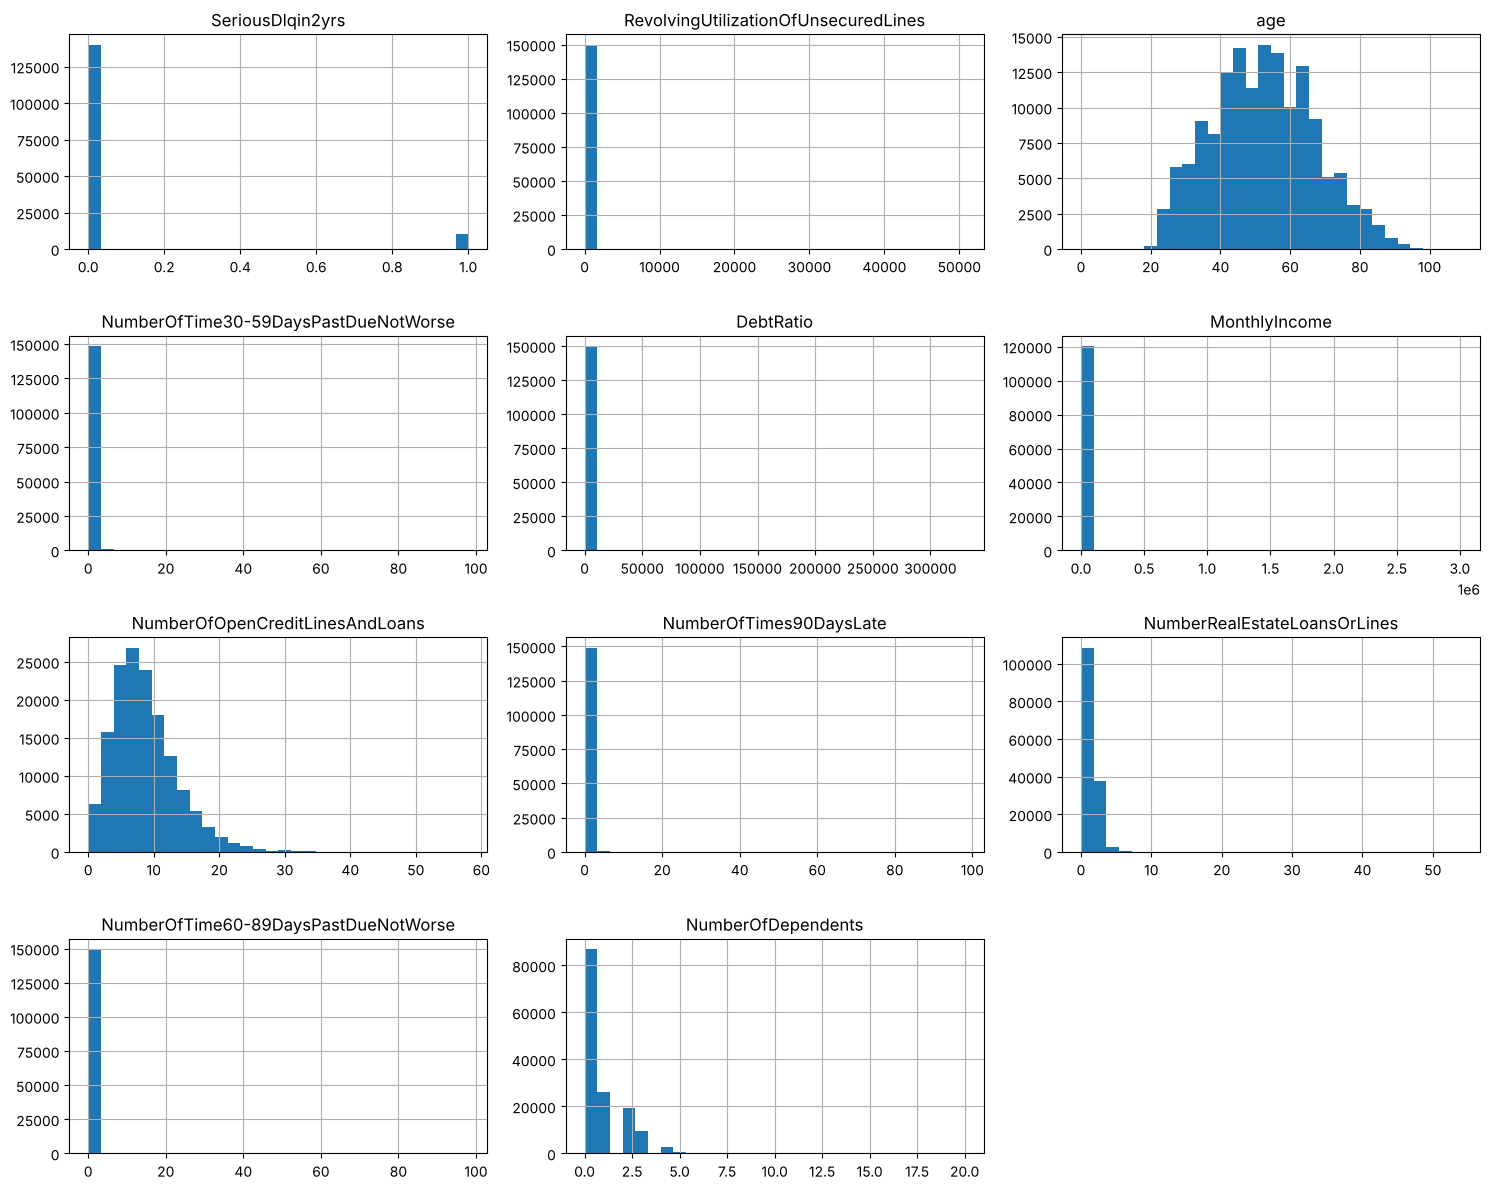

outlier detection


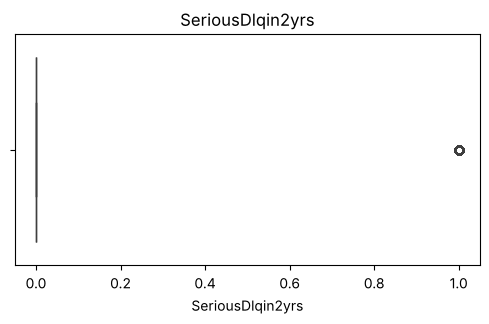

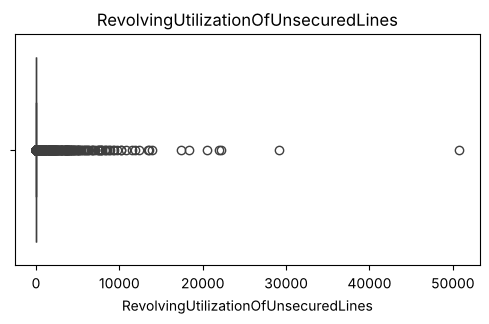

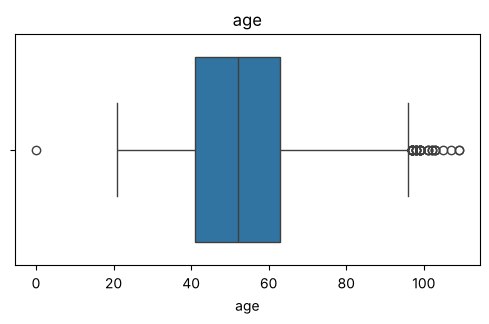

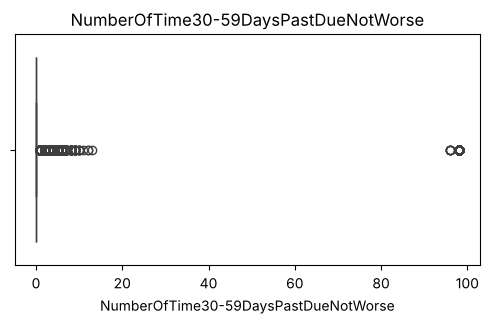

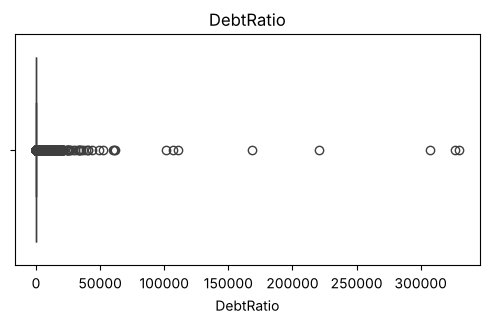

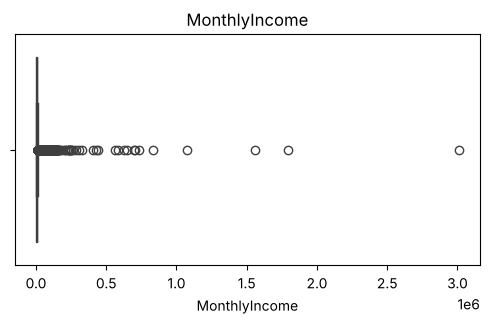

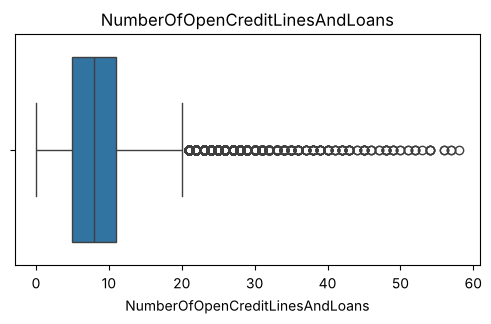

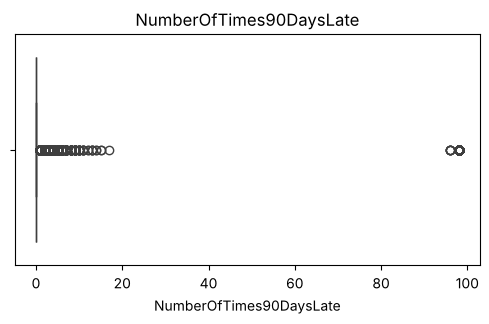

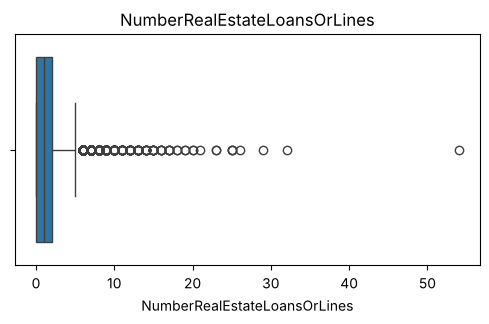

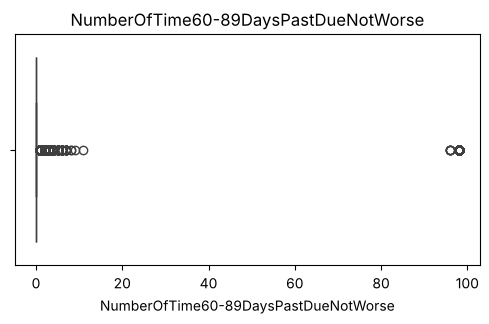

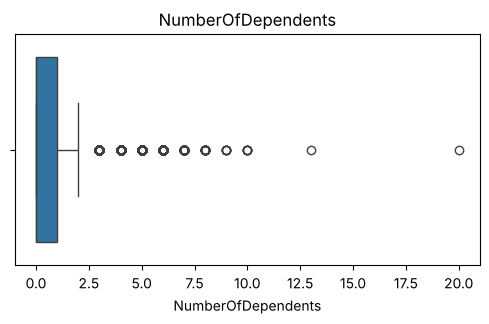

In [9]:
df.hist(figsize=(15,12), bins=30)
plt.tight_layout()
plt.show()
#Outlier detection
print("outlier detection")
numeric_cols = df.select_dtypes(include=['int64','float64']).columns
for col in numeric_cols:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

In [10]:
import os
import warnings
from pathlib import Path
from urllib.request import urlopen

import joblib
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
print("All imports done | scikit-learn", sklearn.__version__, "| mlflow", mlflow.__version__)

All imports done | scikit-learn 1.9.1 | mlflow 3.18.0


In [11]:
df = pd.read_csv(find_data())
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
print("Shape:", df.shape)
df.head(3)

Shape: (150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0


In [12]:
# 1. Remove age errors (for eg 0 years old)
df = df[df["age"] >= 18]
# 2. Fill missing MonthlyIncome with median
income_median = df["MonthlyIncome"].median()
df["MonthlyIncome"] = df["MonthlyIncome"].fillna(income_median)
# 3. Fill missing NumberOfDependents with median
dep_median = df["NumberOfDependents"].median()
df["NumberOfDependents"] = df["NumberOfDependents"].fillna(dep_median)
# 4. Clip extreme outliers
df["DebtRatio"] = df["DebtRatio"].clip(upper=df["DebtRatio"].quantile(0.99))
df["MonthlyIncome"] = df["MonthlyIncome"].clip(upper=df["MonthlyIncome"].quantile(0.99))
df["RevolvingUtilizationOfUnsecuredLines"] = df["RevolvingUtilizationOfUnsecuredLines"].clip(upper=1.0)
# Verify no nulls remain
print("Nulls remaining:", df.isnull().sum().sum())
print("Shape after cleaning:", df.shape)

Nulls remaining: 0
Shape after cleaning: (149999, 11)


In [13]:
X = df.drop(columns=["SeriousDlqin2yrs"])
y = df["SeriousDlqin2yrs"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature columns:", X.columns.tolist())
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,        #93/7 ratio in both splits
    random_state=42
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)
print("\nTarget distribution in train:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

Features shape: (149999, 10)
Target shape: (149999,)

Feature columns: ['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']


Train size: (119999, 10)
Test size: (30000, 10)

Target distribution in train:
SeriousDlqin2yrs
0    93.32
1     6.68
Name: proportion, dtype: float64


In [14]:
# All columns are numerical in this dataset
numerical_cols = X.columns.tolist()
print("Numerical columns:", numerical_cols)
# Build preprocessor
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numerical_cols)
])
# Building full pipeline with RandomForest as first model
pipeline_rf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",   # handles the 93/7 imbalance
        random_state=42,
        n_jobs=-1
    ))
])

print("Pipeline built successfully!")
print(pipeline_rf)

Numerical columns: ['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']
Pipeline built successfully!
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['RevolvingUtilizationOfUnsecuredLines',
                                                   'age',
                                                   'NumberOfTime30-59DaysPastDueNotWorse',
                                                   'DebtRatio', 'MonthlyIncome',
                                                   'NumberOfOpenCreditLinesAndLoans',
                                                   'NumberOfTimes90DaysLate',
                                                   'NumberRealEstateLoansOrLines',
  

In [15]:
# --- MLflow setup: use the local server if it is running, otherwise log to a local SQLite file ---
def mlflow_server_up(url="http://localhost:5000", timeout=2):
    try:
        urlopen(f"{url}/health", timeout=timeout)
        return True
    except Exception:
        return False


if mlflow_server_up():
    mlflow.set_tracking_uri("http://localhost:5000")
else:
    mlflow.set_tracking_uri("sqlite:///mlflow.db")
    print("MLflow server not running -> logging to ./mlflow.db")
    print("View runs with:  mlflow ui --backend-store-uri sqlite:///mlflow.db")

mlflow.set_experiment("loans-default-prediction")
print("Tracking URI:", mlflow.get_tracking_uri())


def train_and_log(run_name, pipeline, params):
    """Fit one pipeline, log params/metrics/model to MLflow, return the metrics."""
    with mlflow.start_run(run_name=run_name):
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)
        y_prob = pipeline.predict_proba(X_test)[:, 1]

        metrics = {
            "f1_score": f1_score(y_test, y_pred),
            "roc_auc": roc_auc_score(y_test, y_prob),
            "precision": precision_score(y_test, y_pred),
            "recall": recall_score(y_test, y_pred),
        }
        mlflow.log_params(params)
        mlflow.log_metrics(metrics)
        # cloudpickle: newer MLflow defaults to 'skops', which rejects tree models (RF / GB)
        try:
            mlflow.sklearn.log_model(pipeline, name="model", serialization_format="cloudpickle")            # MLflow 3.x
        except TypeError:
            mlflow.sklearn.log_model(pipeline, artifact_path="model", serialization_format="cloudpickle")   # MLflow 2.x

    print(f"=== {run_name} ===")
    for k, v in metrics.items():
        print(f"{k:<10}: {v:.4f}")
    return metrics

MLflow server not running -> logging to ./mlflow.db
View runs with:  mlflow ui --backend-store-uri sqlite:///mlflow.db


2026/11/14 14:56:14 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/14 14:56:14 INFO mlflow.store.db.utils: Updating database tables


2026/11/14 14:56:15 INFO mlflow.tracking.fluent: Experiment with name 'loans-default-prediction' does not exist. Creating a new experiment.


Tracking URI: sqlite:///mlflow.db


In [16]:
# Random Forest (pipeline_rf was built above) and Logistic Regression
train_and_log("RandomForest-v1", pipeline_rf,
              {"model": "RandomForest", "n_estimators": 100, "class_weight": "balanced"})

pipeline_lr = Pipeline(steps=[
    ("preprocessor", ColumnTransformer(transformers=[("num", StandardScaler(), numerical_cols)])),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
])
train_and_log("LogisticRegression-v1", pipeline_lr,
              {"model": "LogisticRegression", "class_weight": "balanced", "max_iter": 1000})

2026/11/14 14:56:33 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


=== RandomForest-v1 ===
f1_score  : 0.3952
roc_auc   : 0.8421
precision : 0.4336
recall    : 0.3631


2026/11/14 14:56:40 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


=== LogisticRegression-v1 ===
f1_score  : 0.2964
roc_auc   : 0.8339
precision : 0.1846
recall    : 0.7511


{'f1_score': 0.2963983467821295,
 'roc_auc': 0.8338973160062871,
 'precision': 0.18462670099301215,
 'recall': 0.7511221945137158}

In [17]:
pipeline_gb = Pipeline(steps=[
    ("preprocessor", ColumnTransformer(transformers=[("num", StandardScaler(), numerical_cols)])),
    ("model", GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)),
])
train_and_log("GradientBoosting-v1", pipeline_gb,
              {"model": "GradientBoosting", "n_estimators": 100, "learning_rate": 0.1})

2026/11/14 14:57:02 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


=== GradientBoosting-v1 ===
f1_score  : 0.3084
roc_auc   : 0.8681
precision : 0.5921
recall    : 0.2085


{'f1_score': 0.3083732939874585,
 'roc_auc': 0.8680800410119548,
 'precision': 0.5920679886685553,
 'recall': 0.2084788029925187}

In [18]:
results = {
    "RandomForest": pipeline_rf,
    "LogisticRegression": pipeline_lr,
    "GradientBoosting": pipeline_gb,
}

print(f"{'Model':<25} {'ROC-AUC':>10} {'F1':>10} {'Precision':>10} {'Recall':>10}")
print("-" * 70)

scores = {}
for name, pipeline in results.items():
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_prob)
    f1  = f1_score(y_test, y_pred)
    pre = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    scores[name] = auc
    print(f"{name:<25} {auc:>10.4f} {f1:>10.4f} {pre:>10.4f} {rec:>10.4f}")

best_model_name = max(scores, key=scores.get)
print(f"\nBest model by ROC-AUC: {best_model_name}")

Model                        ROC-AUC         F1  Precision     Recall
----------------------------------------------------------------------


RandomForest                  0.8421     0.3952     0.4336     0.3631
LogisticRegression            0.8339     0.2964     0.1846     0.7511
GradientBoosting              0.8681     0.3084     0.5921     0.2085

Best model by ROC-AUC: GradientBoosting


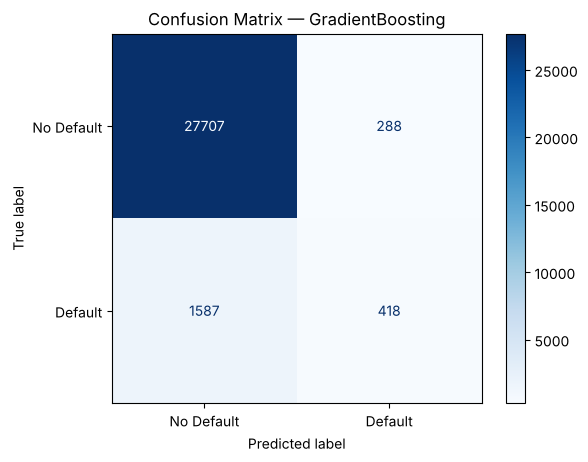


Full Classification Report:
              precision    recall  f1-score   support

  No Default       0.95      0.99      0.97     27995
     Default       0.59      0.21      0.31      2005

    accuracy                           0.94     30000
   macro avg       0.77      0.60      0.64     30000
weighted avg       0.92      0.94      0.92     30000



In [19]:
best_pipeline = results[best_model_name]

y_pred_best = best_pipeline.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Default", "Default"])
disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.show()

print("\nFull Classification Report:")
print(classification_report(y_test, y_pred_best, target_names=["No Default", "Default"]))

In [20]:
# Save into <repo>/models whether the notebook runs from the repo root or from notebooks/
MODELS_DIR = Path("..") / "models" if (Path("..") / "data").exists() and not Path("data").exists() else Path("models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(best_pipeline, MODELS_DIR / "best_pipeline.pkl")

model = joblib.load(MODELS_DIR / "best_pipeline.pkl")
print("Saved and reloaded OK:", best_model_name, "->", MODELS_DIR / "best_pipeline.pkl")
print("Pin this in requirements.txt -> scikit-learn==" + sklearn.__version__)

Saved and reloaded OK: GradientBoosting -> ../models/best_pipeline.pkl
Pin this in requirements.txt -> scikit-learn==1.9.1
